In [1]:
# Cellule : Dataset MILES pour XGBoost

import pandas as pd
import numpy as np
from datetime import datetime, timedelta

np.random.seed(42)
n_lignes = 1500

# 1. CREDITSCORE.REQUESTEDAMOUNT
amount = np.random.normal(15000, 5000, n_lignes)
amount[amount < 0] = np.random.normal(10000, 2000, sum(amount < 0))

# 2. CREDITSCORE.AUTHORIZEDAMOUNT
amount_autorise = amount * np.random.uniform(0.7, 1.0, n_lignes)
amount_autorise[amount_autorise < 0] = 5000

# 3. LEASESERVICE.DURATION
duration = np.random.normal(36, 12, n_lignes)
duration[duration < 0] = 12
duration[duration > 120] = 120

# 4. LEASESERVICE.INTERESTRATE
interest_rate = np.random.normal(4.5, 1.0, n_lignes)
interest_rate[interest_rate < 0] = 3.0
interest_rate[interest_rate > 10] = 8.0

# 5. BUSINESSPARTNER.ESTABLISHMENTDATE (anciennete_client)
reference_date = datetime(2024, 12, 31)
establishment_dates = []
for _ in range(n_lignes):
    annees = np.random.randint(1, 41)
    date = reference_date - timedelta(days=annees * 365 + np.random.randint(0, 365))
    establishment_dates.append(date)
anciennete_client = [(reference_date - date).days / 365.25 for date in establishment_dates]

# 6. CREDITSCORE.NUMERICSCORE
credit_score = np.random.normal(700, 80, n_lignes)
credit_score[credit_score < 300] = np.random.normal(500, 50, sum(credit_score < 300))
credit_score[credit_score > 900] = 850

# 7. CREDITSCORE.RISKPERCENTAGE
risk_percentage = 100 - (credit_score - 300) / 6
risk_percentage[risk_percentage < 0] = 5
risk_percentage[risk_percentage > 95] = 95

# 8. CONTRACT.STARTDATE (anciennete_contrat)
start_dates = []
for _ in range(n_lignes):
    annees = np.random.randint(0, 11)
    date = reference_date - timedelta(days=annees * 365 + np.random.randint(0, 365))
    start_dates.append(date)
anciennete_contrat = [(reference_date - date).days / 365.25 for date in start_dates]

# 9. Créer le label is_anomaly (basé sur des règles métier simplifiées)
is_anomaly = np.zeros(n_lignes)
# Anomalie 1 : Montant demandé très élevé + durée longue + score faible
is_anomaly[(amount > 30000) & (duration > 48) & (credit_score < 600)] = 1
# Anomalie 2 : Montant négatif
is_anomaly[amount < 0] = 1
# Anomalie 3 : Contrat récent (anciennete_contrat < 1 an) avec montant très élevé
is_anomaly[(anciennete_contrat < 1) & (amount > 35000)] = 1
# Anomalie 4 : Client ancien (> 30 ans) avec contrat récent et montant élevé
is_anomaly[(anciennete_client > 30) & (anciennete_contrat < 1) & (amount > 30000)] = 1

# Créer le DataFrame
df_miles = pd.DataFrame({
    'amount': amount,
    'amount_autorise': amount_autorise,
    'duration': duration,
    'interest_rate': interest_rate,
    'anciennete_client': anciennete_client,
    'credit_score': credit_score,
    'risk_percentage': risk_percentage,
    'anciennete_contrat': anciennete_contrat,
    'is_anomaly': is_anomaly
})

print("✅ Dataset MILES créé")
print(f"   - {len(df_miles)} lignes")
print(f"   - {int(df_miles['is_anomaly'].sum())} anomalies ({df_miles['is_anomaly'].mean()*100:.1f}%)")
print(f"   - Colonnes : {list(df_miles.columns)}")
df_miles.head()

TypeError: '<' not supported between instances of 'list' and 'int'

In [14]:
# Cellule 1 : Dataset MILES pour XGBoost (CORRIGÉ)

import pandas as pd
import numpy as np
from datetime import datetime, timedelta

np.random.seed(42)
n_lignes = 1500

# --- 1. Générer des données normales ---
# CREDITSCORE.REQUESTEDAMOUNT
amount = np.random.normal(15000, 5000, n_lignes)
amount[amount < 0] = np.random.normal(10000, 2000, sum(amount < 0))

# CREDITSCORE.AUTHORIZEDAMOUNT
amount_autorise = amount * np.random.uniform(0.7, 1.0, n_lignes)
amount_autorise[amount_autorise < 0] = 5000

# LEASESERVICE.DURATION
duration = np.random.normal(36, 12, n_lignes)
duration[duration < 0] = 12
duration[duration > 120] = 120

# LEASESERVICE.INTERESTRATE
interest_rate = np.random.normal(4.5, 1.0, n_lignes)
interest_rate[interest_rate < 0] = 3.0
interest_rate[interest_rate > 10] = 8.0

# BUSINESSPARTNER.ESTABLISHMENTDATE (anciennete_client)
reference_date = datetime(2024, 12, 31)
anciennete_client = np.random.uniform(1, 40, n_lignes)

# CREDITSCORE.NUMERICSCORE
credit_score = np.random.normal(700, 80, n_lignes)
credit_score[credit_score < 300] = np.random.normal(500, 50, sum(credit_score < 300))
credit_score[credit_score > 900] = 850

# CREDITSCORE.RISKPERCENTAGE
risk_percentage = 100 - (credit_score - 300) / 6
risk_percentage[risk_percentage < 0] = 5
risk_percentage[risk_percentage > 95] = 95

# CONTRACT.STARTDATE (anciennete_contrat)
anciennete_contrat = np.random.uniform(0, 10, n_lignes)

# --- 2. Ajouter DES ANOMALIES (au moins 10%) ---
# On va modifier certaines lignes pour créer des anomalies
n_anomalies = int(n_lignes * 0.12)  # 12% d'anomalies

# Créer une copie des données normales
df_normal = pd.DataFrame({
    'amount': amount,
    'amount_autorise': amount_autorise,
    'duration': duration,
    'interest_rate': interest_rate,
    'anciennete_client': anciennete_client,
    'credit_score': credit_score,
    'risk_percentage': risk_percentage,
    'anciennete_contrat': anciennete_contrat
})

# Créer des anomalies
np.random.seed(99)
indices_anomalies = np.random.choice(n_lignes, n_anomalies, replace=False)

df_anomalies = df_normal.iloc[indices_anomalies].copy()

# Appliquer différents types d'anomalies
for i, idx in enumerate(indices_anomalies):
    type_anomalie = i % 5
    
    if type_anomalie == 0:
        # Anomalie 1 : Montant très élevé + durée longue + score bas
        df_anomalies.loc[idx, 'amount'] = np.random.uniform(40000, 70000)
        df_anomalies.loc[idx, 'duration'] = np.random.uniform(180, 300)
        df_anomalies.loc[idx, 'credit_score'] = np.random.uniform(250, 450)
    
    elif type_anomalie == 1:
        # Anomalie 2 : Montant négatif
        df_anomalies.loc[idx, 'amount'] = np.random.uniform(-10000, -1000)
    
    elif type_anomalie == 2:
        # Anomalie 3 : Contrat récent (anciennete_contrat < 0.5) + montant très élevé
        df_anomalies.loc[idx, 'anciennete_contrat'] = np.random.uniform(0, 0.3)
        df_anomalies.loc[idx, 'amount'] = np.random.uniform(35000, 60000)
    
    elif type_anomalie == 3:
        # Anomalie 4 : Client très ancien + contrat récent + montant élevé
        df_anomalies.loc[idx, 'anciennete_client'] = np.random.uniform(35, 45)
        df_anomalies.loc[idx, 'anciennete_contrat'] = np.random.uniform(0, 0.3)
        df_anomalies.loc[idx, 'amount'] = np.random.uniform(30000, 50000)
    
    else:
        # Anomalie 5 : Durée très courte + montant élevé
        df_anomalies.loc[idx, 'duration'] = np.random.uniform(1, 5)
        df_anomalies.loc[idx, 'amount'] = np.random.uniform(25000, 45000)

# --- 3. Fusionner et créer le label ---
# Marquer les anomalies
df_anomalies['is_anomaly'] = 1
df_normal['is_anomaly'] = 0

# Fusionner
df_miles = pd.concat([df_normal, df_anomalies], ignore_index=True)

# Mélanger
df_miles = df_miles.sample(frac=1, random_state=42).reset_index(drop=True)

print("✅ Dataset MILES créé avec anomalies")
print(f"   - {len(df_miles)} lignes")
print(f"   - {df_miles['is_anomaly'].sum()} anomalies ({df_miles['is_anomaly'].mean()*100:.1f}%)")
print(f"   - Colonnes : {list(df_miles.columns)}")
df_miles.head()

✅ Dataset MILES créé avec anomalies
   - 1680 lignes
   - 180 anomalies (10.7%)
   - Colonnes : ['amount', 'amount_autorise', 'duration', 'interest_rate', 'anciennete_client', 'credit_score', 'risk_percentage', 'anciennete_contrat', 'is_anomaly']


,amount,amount_autorise,duration,interest_rate,anciennete_client,credit_score,risk_percentage,anciennete_contrat,is_anomaly
0,39274.892481,13196.070804,41.702013,4.741240,42.374641,707.986105,32.002316,0.167390,1
1,6967.768399,5211.942888,13.439880,4.301804,21.570802,547.264203,58.789299,7.538035,0
2,20269.010260,17476.713433,33.893233,4.762067,18.048776,754.010965,24.331506,4.752465,0
3,6184.799223,5250.513221,46.744265,5.259515,20.011246,665.681543,39.053076,2.978473,0
4,18541.782236,15628.881597,40.896634,6.775825,6.821452,715.289939,30.785010,2.866592,0


In [6]:
# Cellule 1.5 : Sauvegarder le dataset MILES en CSV

import os

# 1. Créer le dossier DataX s'il n'existe pas
os.makedirs("../DataX", exist_ok=True)

# 2. Définir le chemin du fichier
chemin_dataset = "../DataX/dataset_miles_xgboost.csv"

# 3. Sauvegarder le DataFrame
df_miles.to_csv(chemin_dataset, index=False)

print(f"✅ Dataset sauvegardé avec succès !")
print(f"   📁 Chemin : {chemin_dataset}")
print(f"   📊 Lignes : {len(df_miles)}")
print(f"   📋 Colonnes : {list(df_miles.columns)}")

✅ Dataset sauvegardé avec succès !
   📁 Chemin : ../DataX/dataset_miles_xgboost.csv
   📊 Lignes : 1680
   📋 Colonnes : ['amount', 'amount_autorise', 'duration', 'interest_rate', 'anciennete_client', 'credit_score', 'risk_percentage', 'anciennete_contrat', 'is_anomaly']


In [15]:
# Cellule 2 : Entraîner XGBoost avec colonnes MILES

from ia_models_avances import XGBoostAnomalyDetector

features_miles = [
    'amount', 'amount_autorise', 'duration', 'interest_rate',
    'anciennete_client', 'credit_score', 'risk_percentage', 'anciennete_contrat'
]

model_miles = XGBoostAnomalyDetector()
model_miles.fit(
    df_miles,
    target_col='is_anomaly',
    features=features_miles,
    test_size=0.2
)

print("\n📊 RÉSULTATS XGBoost (MILES)")
print("=" * 60)
print(f"   Précision : {model_miles.metrics['accuracy']:.2%}")
print(f"   F1-Score : {model_miles.metrics['f1_score']:.2%}")
print(f"   ROC AUC : {model_miles.metrics['roc_auc']:.2%}")

print("\n📊 Importance des caractéristiques :")
for feature, imp in sorted(model_miles.get_importance().items(), key=lambda x: x[1], reverse=True):
    print(f"   - {feature} : {imp:.2%}")


🧠 Entraînement XGBoost + SHAP...
   ✅ Modèle entraîné
   🎯 Précision : 99.70%
   🎯 ROC AUC : 100.00%
   📊 F1-Score (anomalies) : 98.63%

📊 RÉSULTATS XGBoost (MILES)
   Précision : 99.70%
   F1-Score : 98.63%
   ROC AUC : 100.00%

📊 Importance des caractéristiques :
   - amount : 58.87%
   - anciennete_contrat : 11.96%
   - duration : 11.84%
   - credit_score : 8.30%
   - anciennete_client : 3.42%
   - amount_autorise : 2.46%
   - interest_rate : 2.34%
   - risk_percentage : 0.83%


🔍 SHAP - Analyse du modèle XGBoost (12% anomalies)

📊 Préparation des données SHAP...
   ✅ 1680 lignes préparées

🧮 Calcul des valeurs SHAP (peut prendre 1-2 minutes)...
   ✅ Calcul terminé

📊 Génération du graphique SHAP...


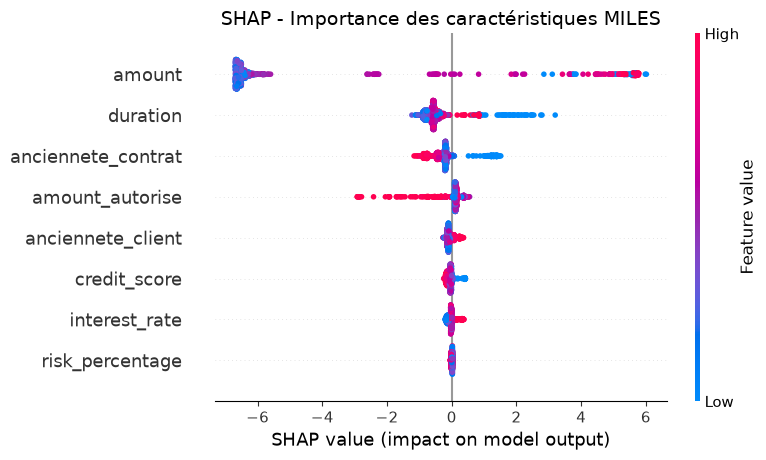

💾 Image sauvegardée : docs/shap_miles_summary.png

📊 SHAP - Bar Plot des importances moyennes...


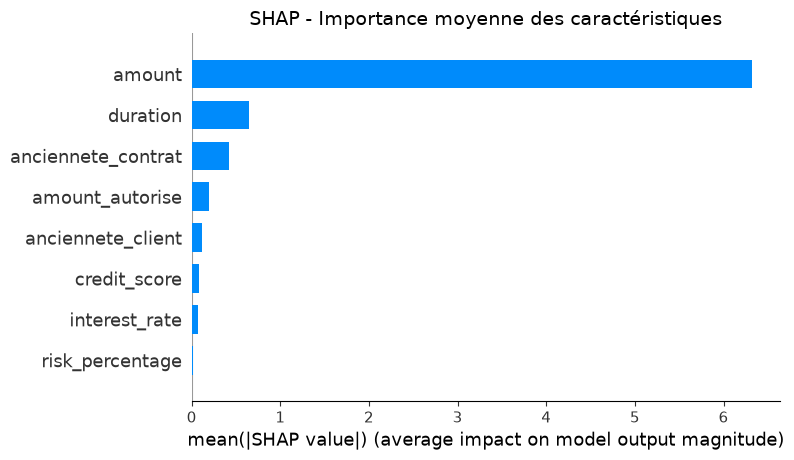

💾 Image sauvegardée : docs/shap_miles_bar.png

📋 GÉNÉRATION DE RÈGLES COMPOSITES

📊 Données analysées :
   - Total : 1680 lignes
   - Anomalies : 182 (10.8%)
   - Normales : 1498

🔍 Analyse SHAP des anomalies...
   ✅ 182 anomalies analysées

📋 TOP 5 RÈGLES COMPOSITES GÉNÉRÉES :
------------------------------------------------------------

1. amount > 33060 AND anciennete_contrat > 3 AND amount_autorise > 13007
   → Features : amount, anciennete_contrat, amount_autorise
   → Impact SHAP : 5.598, 1.302, 0.372

2. amount > 33060 AND anciennete_contrat > 3 AND duration < 68
   → Features : amount, anciennete_contrat, duration
   → Impact SHAP : 3.645, 1.415, -0.465

3. amount > 33060 AND duration > 68 AND credit_score > 628
   → Features : amount, duration, credit_score
   → Impact SHAP : 5.699, 0.833, 0.394

4. amount > 33060 AND anciennete_contrat > 3 AND amount_autorise > 13007
   → Features : amount, anciennete_contrat, amount_autorise
   → Impact SHAP : 4.868, 1.391, 0.413

5. amount 

In [16]:
# Cellule 3 : SHAP - Analyse du modèle 12% et génération de règles composites

import shap
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

print("=" * 60)
print("🔍 SHAP - Analyse du modèle XGBoost (12% anomalies)")
print("=" * 60)

# 1. Préparer les données pour SHAP
print("\n📊 Préparation des données SHAP...")
data = df_miles[features_miles].copy()
for col in features_miles:
    data[col] = data[col].fillna(data[col].mean())

data_scaled = model_miles.scaler.transform(data)
print(f"   ✅ {len(data)} lignes préparées")

# 2. Calculer les valeurs SHAP
print("\n🧮 Calcul des valeurs SHAP (peut prendre 1-2 minutes)...")
shap_values = model_miles.shap_explainer.shap_values(data_scaled)
print("   ✅ Calcul terminé")

# 3. Graphique SHAP - Summary Plot
print("\n📊 Génération du graphique SHAP...")
plt.figure(figsize=(12, 8))
shap.summary_plot(shap_values, data_scaled, feature_names=features_miles, show=False)
plt.title("SHAP - Importance des caractéristiques MILES", fontsize=14)
plt.tight_layout()
plt.savefig("../docs/shap_miles_summary.png", dpi=300, bbox_inches='tight')
plt.show()
print("💾 Image sauvegardée : docs/shap_miles_summary.png")

# 4. Graphique SHAP - Bar Plot
print("\n📊 SHAP - Bar Plot des importances moyennes...")
shap.summary_plot(shap_values, data_scaled, feature_names=features_miles, plot_type="bar", show=False)
plt.title("SHAP - Importance moyenne des caractéristiques", fontsize=14)
plt.tight_layout()
plt.savefig("../docs/shap_miles_bar.png", dpi=300, bbox_inches='tight')
plt.show()
print("💾 Image sauvegardée : docs/shap_miles_bar.png")

# 5. Génération des règles composites
print("\n📋 GÉNÉRATION DE RÈGLES COMPOSITES")

df_resultats = model_miles.predict(df_miles)
anomalies = df_miles[df_resultats['is_anomaly'] == True]
normales = df_miles[df_resultats['is_anomaly'] == False]

print(f"\n📊 Données analysées :")
print(f"   - Total : {len(df_miles)} lignes")
print(f"   - Anomalies : {len(anomalies)} ({len(anomalies)/len(df_miles)*100:.1f}%)")
print(f"   - Normales : {len(normales)}")

if len(anomalies) == 0:
    print("⚠️ Aucune anomalie trouvée. Vérifiez le dataset.")
else:
    # Obtenir les explications SHAP pour les anomalies
    print("\n🔍 Analyse SHAP des anomalies...")
    explanations = model_miles.explain(anomalies)
    print(f"   ✅ {len(explanations)} anomalies analysées")

    # Générer les règles composites
    print("\n📋 TOP 5 RÈGLES COMPOSITES GÉNÉRÉES :")
    print("-" * 60)

    regles_composites = []

    for i, (idx, row) in enumerate(anomalies.iterrows()):
        if i >= len(explanations):
            break
        expl = explanations[i]
        conditions = []

        for feature, value in expl['top_features'][:3]:
            if value > 0:
                seuil = anomalies[feature].mean()
                conditions.append(f"{feature} > {seuil:.0f}")
            else:
                seuil = anomalies[feature].mean()
                conditions.append(f"{feature} < {seuil:.0f}")

        regle_composite = " AND ".join(conditions)
        regles_composites.append({
            'regle': regle_composite,
            'conditions': conditions,
            'features': [f[0] for f in expl['top_features'][:3]],
            'shap_values': [f[1] for f in expl['top_features'][:3]]
        })

        if i < 5:
            print(f"\n{i+1}. {regle_composite}")
            print(f"   → Features : {', '.join([f[0] for f in expl['top_features'][:3]])}")
            print(f"   → Impact SHAP : {', '.join([f'{f[1]:.3f}' for f in expl['top_features'][:3]])}")

    # Sauvegarder les règles composites
    df_regles_composites = pd.DataFrame(regles_composites)
    df_regles_composites.to_csv("../DataX/regles_composites_shap.csv", index=False)
    print(f"\n💾 {len(regles_composites)} règles composites sauvegardées : DataX/regles_composites_shap.csv")

    # 6. Exporter les règles en format SQL (intégrable dans le référentiel)
    print("\n📝 FORMAT SQL (INTÉGRABLE DANS LE RÉFÉRENTIEL)")
    print("-" * 60)

    for i, regle in enumerate(regles_composites[:5], 1):
        nom_regle = f"SHAP_COMPOSITE_{i:03d}"
        description = f"Règle composite générée par SHAP : {regle['regle']}"
        expression = f"SELECT * FROM CONTRACT WHERE {regle['regle']}"

        print(f"\n-- Règle #{i}")
        print(f"INSERT INTO Regles (REGLE_ID, NOM_REGLE, DESCRIPTION, EXPRESSION_SQL)")
        print(f"VALUES (")
        print(f"    '{nom_regle}',")
        print(f"    'Règle SHAP - {', '.join(regle['features'][:3])}',")
        print(f"    '{description}',")
        print(f"    '{expression}'")
        print(f");")

print("\n" + "=" * 60)
print("🏁 FIN - SHAP terminé avec succès !")
print("=" * 60)

📊 GRAPHIQUES COMPLÉMENTAIRES - ANALYSE MILES

1️⃣ Matrice de corrélation des caractéristiques...


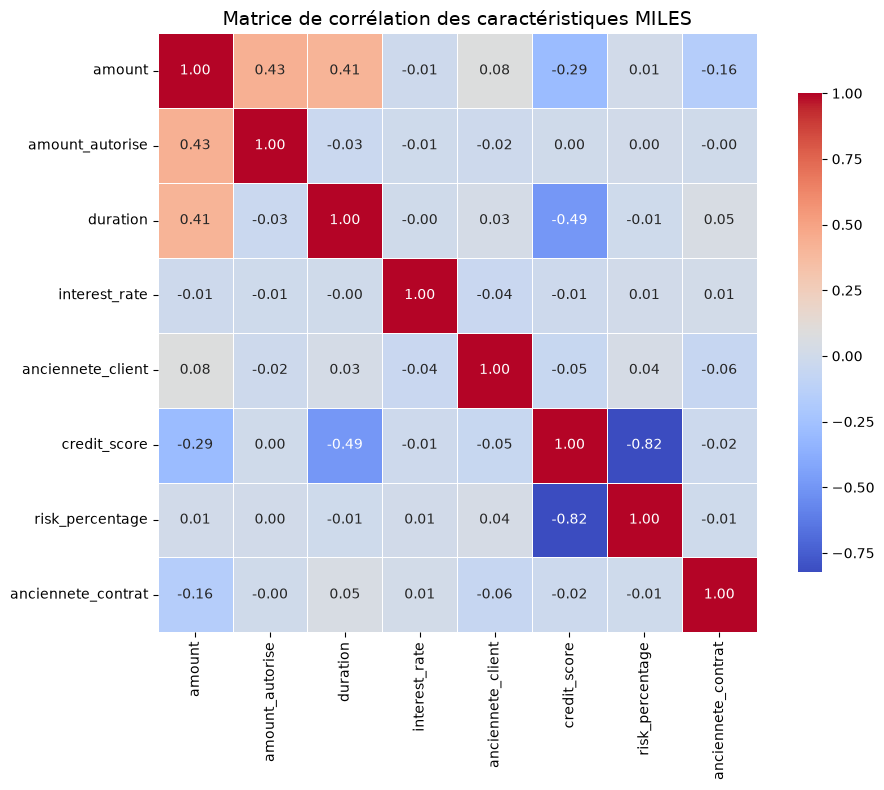

💾 Sauvegardé : docs/matrice_correlation_miles.png

2️⃣ Taux d'anomalies par catégorie de montant...


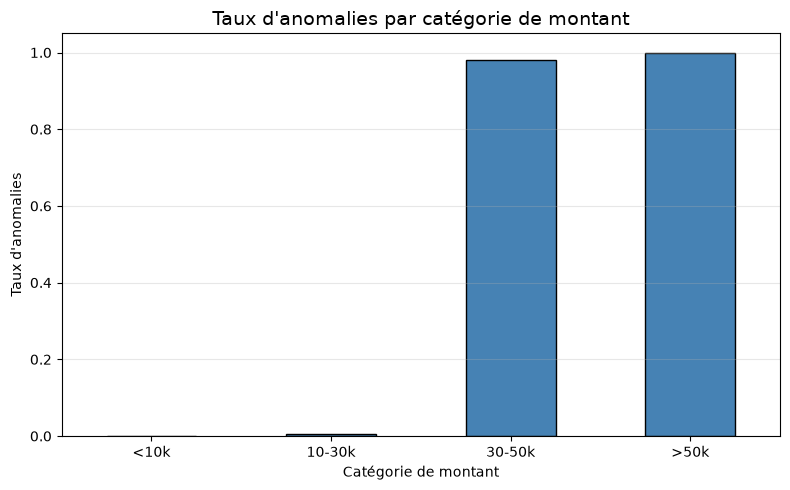

💾 Sauvegardé : docs/anomalies_par_montant_miles.png

3️⃣ Taux d'anomalies par ancienneté du contrat...


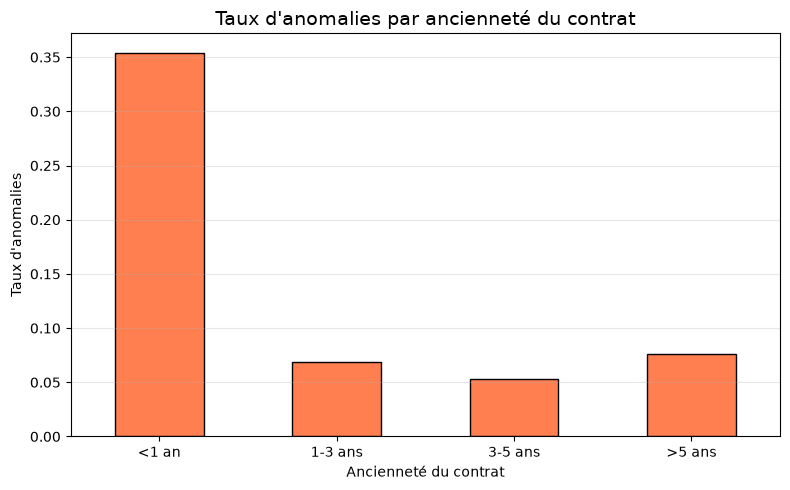

💾 Sauvegardé : docs/anomalies_par_anciennete_miles.png

4️⃣ Pairplot des principales caractéristiques (peut prendre du temps)...


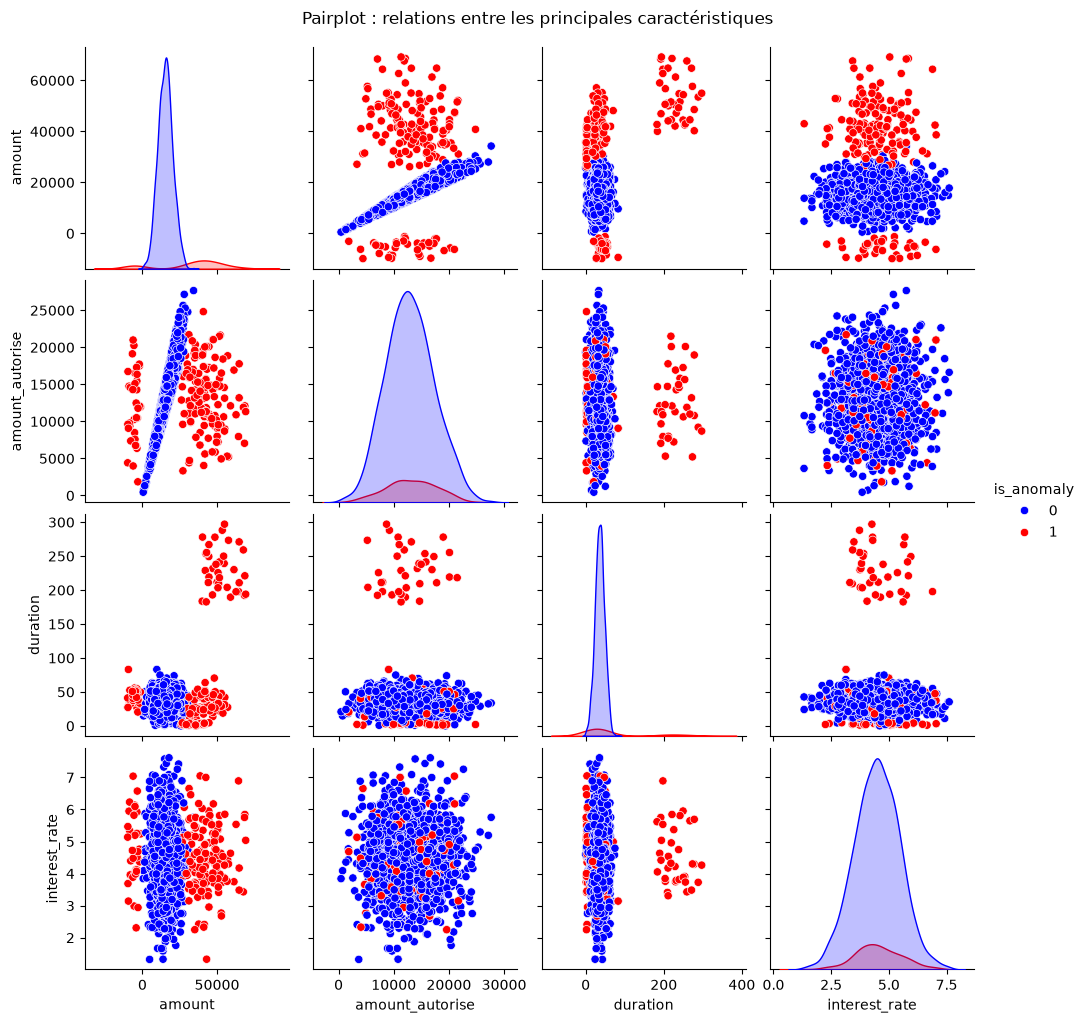

💾 Sauvegardé : docs/pairplot_miles.png

🏁 FIN - Graphiques complémentaires générés avec succès !


In [17]:
# Cellule 4 : Graphiques complémentaires d'analyse des données MILES

import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

print("=" * 60)
print("📊 GRAPHIQUES COMPLÉMENTAIRES - ANALYSE MILES")
print("=" * 60)

# 1. Matrice de corrélation (Quantitative - Quantitative)
print("\n1️⃣ Matrice de corrélation des caractéristiques...")
plt.figure(figsize=(10, 8))
corr = df_miles[features_miles].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, 
            square=True, cbar_kws={"shrink": 0.8})
plt.title("Matrice de corrélation des caractéristiques MILES", fontsize=14)
plt.tight_layout()
plt.savefig("../docs/matrice_correlation_miles.png", dpi=300, bbox_inches='tight')
plt.show()
print("💾 Sauvegardé : docs/matrice_correlation_miles.png")

# 2. Distribution des anomalies par catégorie de montant (Quantitative - Qualitative)
print("\n2️⃣ Taux d'anomalies par catégorie de montant...")
df_miles['categorie_montant'] = pd.cut(df_miles['amount'], 
                                        bins=[0, 10000, 30000, 50000, 100000], 
                                        labels=['<10k', '10-30k', '30-50k', '>50k'])
df_group = df_miles.groupby('categorie_montant', observed=False)['is_anomaly'].mean()

plt.figure(figsize=(8, 5))
df_group.plot(kind='bar', color='steelblue', edgecolor='black')
plt.title("Taux d'anomalies par catégorie de montant", fontsize=14)
plt.xlabel("Catégorie de montant")
plt.ylabel("Taux d'anomalies")
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig("../docs/anomalies_par_montant_miles.png", dpi=300, bbox_inches='tight')
plt.show()
print("💾 Sauvegardé : docs/anomalies_par_montant_miles.png")

# 3. Distribution des anomalies par ancienneté du contrat (Quantitative - Qualitative)
print("\n3️⃣ Taux d'anomalies par ancienneté du contrat...")
df_miles['categorie_anciennete'] = pd.cut(df_miles['anciennete_contrat'], 
                                           bins=[0, 1, 3, 5, 10], 
                                           labels=['<1 an', '1-3 ans', '3-5 ans', '>5 ans'])
df_group_anciennete = df_miles.groupby('categorie_anciennete', observed=False)['is_anomaly'].mean()

plt.figure(figsize=(8, 5))
df_group_anciennete.plot(kind='bar', color='coral', edgecolor='black')
plt.title("Taux d'anomalies par ancienneté du contrat", fontsize=14)
plt.xlabel("Ancienneté du contrat")
plt.ylabel("Taux d'anomalies")
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig("../docs/anomalies_par_anciennete_miles.png", dpi=300, bbox_inches='tight')
plt.show()
print("💾 Sauvegardé : docs/anomalies_par_anciennete_miles.png")

# 4. Pairplot des 4 principales caractéristiques (optionnel, peut être long)
print("\n4️⃣ Pairplot des principales caractéristiques (peut prendre du temps)...")
import seaborn as sns
sns.pairplot(df_miles[features_miles[:4] + ['is_anomaly']], hue='is_anomaly', diag_kind='kde', palette=['blue', 'red'])
plt.suptitle("Pairplot : relations entre les principales caractéristiques", y=1.02)
plt.savefig("../docs/pairplot_miles.png", dpi=300, bbox_inches='tight')
plt.show()
print("💾 Sauvegardé : docs/pairplot_miles.png")

print("\n" + "=" * 60)
print("🏁 FIN - Graphiques complémentaires générés avec succès !")
print("=" * 60)

📊 BOXPLOT : Normal vs Anomalie - Toutes les caractéristiques


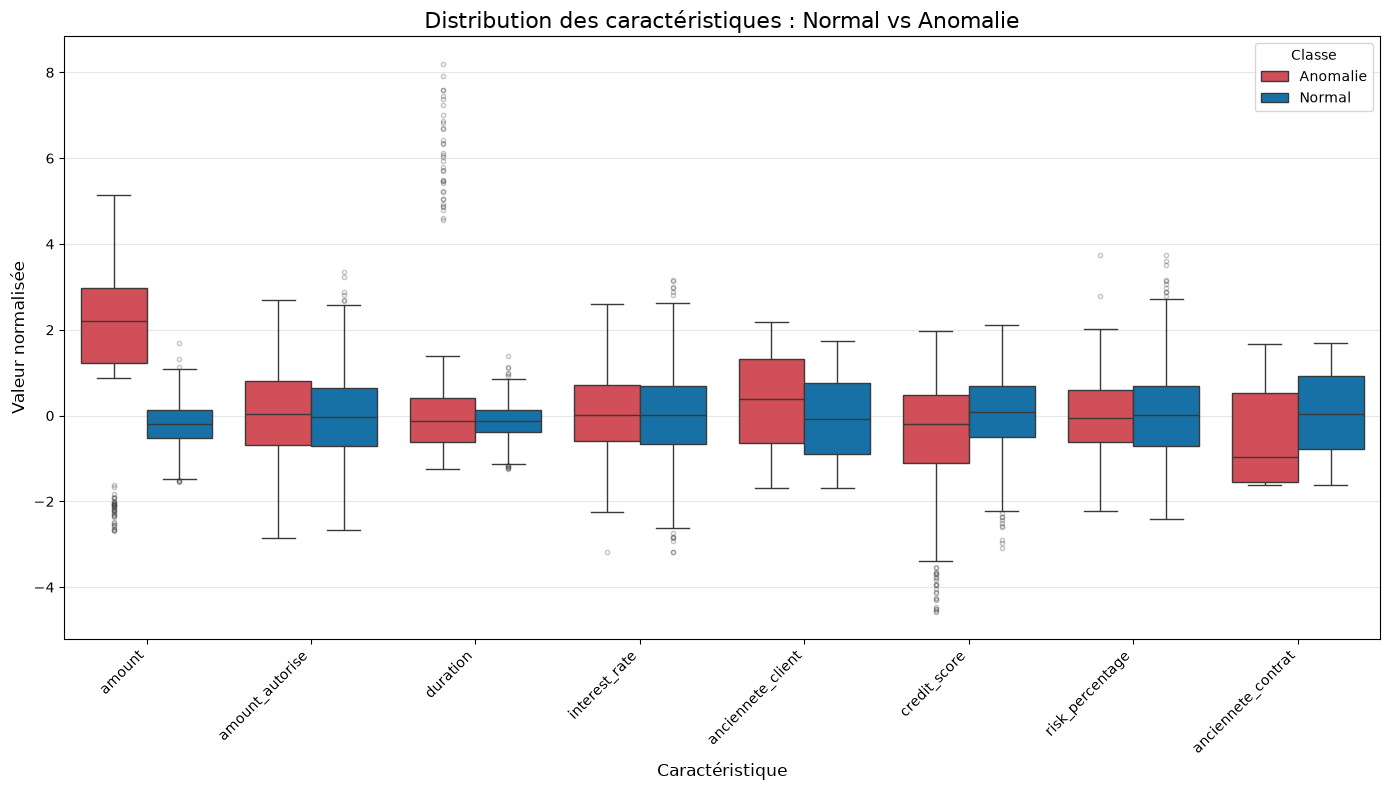

💾 Image sauvegardée : docs/boxplot_normal_vs_anomalie_miles.png


In [18]:
# Cellule : Boxplot comparatif Normal vs Anomalie (toutes les features)

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

print("=" * 60)
print("📊 BOXPLOT : Normal vs Anomalie - Toutes les caractéristiques")
print("=" * 60)

# 1. Récupérer les prédictions du modèle 12%
df_resultats = model_miles.predict(df_miles)
df_miles_plot = df_miles.copy()
df_miles_plot['is_anomaly_pred'] = df_resultats['is_anomaly']
df_miles_plot['type'] = df_miles_plot['is_anomaly_pred'].map({True: 'Anomalie', False: 'Normal'})

# 2. Normaliser les données pour une visualisation cohérente (échelles différentes)
from sklearn.preprocessing import StandardScaler
scaler_plot = StandardScaler()
df_miles_plot_scaled = df_miles_plot.copy()
for col in features_miles:
    df_miles_plot_scaled[col] = scaler_plot.fit_transform(df_miles_plot[[col]])

# 3. Mettre les données au format long pour seaborn
df_melt = df_miles_plot_scaled.melt(
    id_vars=['type'], 
    value_vars=features_miles,
    var_name='Caractéristique', 
    value_name='Valeur normalisée'
)

# 4. Créer le boxplot
plt.figure(figsize=(14, 8))
sns.boxplot(
    data=df_melt,
    x='Caractéristique',
    y='Valeur normalisée',
    hue='type',
    palette={'Normal': '#0077BE', 'Anomalie': '#E63946'},
    showfliers=True,
    flierprops={'marker': 'o', 'markersize': 3, 'alpha': 0.3}
)

plt.title("Distribution des caractéristiques : Normal vs Anomalie", fontsize=16)
plt.xlabel("Caractéristique", fontsize=12)
plt.ylabel("Valeur normalisée", fontsize=12)
plt.legend(title='Classe', loc='upper right')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()

# Sauvegarder
plt.savefig("../docs/boxplot_normal_vs_anomalie_miles.png", dpi=300, bbox_inches='tight')
plt.show()

print("💾 Image sauvegardée : docs/boxplot_normal_vs_anomalie_miles.png")
print("=" * 60)

In [20]:
# Cellule : Nettoyage et déduplication des règles SHAP

df_regles = pd.read_csv("../DataX/regles_composites_shap.csv")

# Supprimer les doublons
df_regles_unique = df_regles.drop_duplicates(subset=['regle'])

print(f"📊 Règles avant déduplication : {len(df_regles)}")
print(f"📊 Règles après déduplication : {len(df_regles_unique)}")

# Sauvegarder les règles uniques
df_regles_unique.to_csv("../DataX/regles_composites_shap_unique.csv", index=False)
print("💾 Règles uniques sauvegardées : DataX/regles_composites_shap_unique.csv")

📊 Règles avant déduplication : 182
📊 Règles après déduplication : 27
💾 Règles uniques sauvegardées : DataX/regles_composites_shap_unique.csv


In [21]:
# Cellule : Intégration des règles SHAP dans le référentiel Excel

import openpyxl
import pandas as pd
import os

print("=" * 60)
print("📝 INTÉGRATION DES RÈGLES SHAP DANS LE RÉFÉRENTIEL")
print("=" * 60)

# 1. Charger les règles SHAP uniques
chemin_regles = "../DataX/regles_composites_shap_unique.csv"

if os.path.exists(chemin_regles):
    df_regles = pd.read_csv(chemin_regles)
    print(f"📊 {len(df_regles)} règles SHAP chargées")
else:
    print("❌ Fichier non trouvé. Vérifiez le chemin.")
    print("   Chemin attendu :", chemin_regles)
    # Tenter de recréer le fichier à partir des données en mémoire
    try:
        df_regles = pd.DataFrame({'regle': regles_composites})
        df_regles = df_regles.drop_duplicates(subset=['regle'])
        df_regles.to_csv(chemin_regles, index=False)
        print(f"✅ Fichier recréé avec {len(df_regles)} règles")
    except:
        print("   Veuillez exécuter d'abord la cellule de déduplication.")
        exit()

# 2. Charger le référentiel Excel
chemin_excel = "../metadata/mon_referentiel_final.xlsx"
if not os.path.exists(chemin_excel):
    print(f"❌ Référentiel Excel non trouvé : {chemin_excel}")
    exit()

wb = openpyxl.load_workbook(chemin_excel)
ws = wb["Regles"]

# 3. Trouver la dernière ligne
derniere_ligne = ws.max_row
print(f"📋 Dernière ligne existante : {derniere_ligne}")

# 4. Ajouter les 10 premières règles (pour éviter de surcharger)
nb_regles_a_ajouter = min(10, len(df_regles))
print(f"📝 Ajout de {nb_regles_a_ajouter} règles SHAP...")

for i in range(nb_regles_a_ajouter):
    regle_sql = df_regles.iloc[i]['regle']
    conditions = regle_sql.split(' AND ')
    features = [c.split(' ')[0] for c in conditions]
    
    ws.cell(row=derniere_ligne + i + 1, column=1, value=f"SHAP_{i+1:03d}")
    ws.cell(row=derniere_ligne + i + 1, column=2, value=f"Règle SHAP - {', '.join(features[:2])}")
    ws.cell(row=derniere_ligne + i + 1, column=3, value=f"Règle composite générée par SHAP : {regle_sql}")
    ws.cell(row=derniere_ligne + i + 1, column=4, value=f"SELECT * FROM CONTRACT WHERE {regle_sql}")

# 5. Sauvegarder
wb.save(chemin_excel)
print(f"✅ {nb_regles_a_ajouter} règles SHAP ajoutées dans l'onglet Regles")
print(f"💾 Référentiel mis à jour : {chemin_excel}")

# 6. Afficher les règles ajoutées
print("\n📋 Règles SHAP ajoutées :")
for i in range(nb_regles_a_ajouter):
    regle_id = ws.cell(row=derniere_ligne + i + 1, column=1).value
    regle_nom = ws.cell(row=derniere_ligne + i + 1, column=2).value
    print(f"   - {regle_id} : {regle_nom}")

print("\n" + "=" * 60)
print("🏁 FIN - Intégration terminée avec succès !")
print("=" * 60)

📝 INTÉGRATION DES RÈGLES SHAP DANS LE RÉFÉRENTIEL
📊 27 règles SHAP chargées
📋 Dernière ligne existante : 9
📝 Ajout de 10 règles SHAP...
✅ 10 règles SHAP ajoutées dans l'onglet Regles
💾 Référentiel mis à jour : ../metadata/mon_referentiel_final.xlsx

📋 Règles SHAP ajoutées :
   - SHAP_001 : Règle SHAP - amount, anciennete_contrat
   - SHAP_002 : Règle SHAP - amount, anciennete_contrat
   - SHAP_003 : Règle SHAP - amount, duration
   - SHAP_004 : Règle SHAP - amount, duration
   - SHAP_005 : Règle SHAP - amount, interest_rate
   - SHAP_006 : Règle SHAP - amount, duration
   - SHAP_007 : Règle SHAP - amount, anciennete_contrat
   - SHAP_008 : Règle SHAP - amount, anciennete_contrat
   - SHAP_009 : Règle SHAP - amount, amount_autorise
   - SHAP_010 : Règle SHAP - duration, amount

🏁 FIN - Intégration terminée avec succès !


In [4]:
# Cellule : Simulation avec 40% d'anomalies (8 types)

import pandas as pd
import numpy as np
from datetime import datetime, timedelta

np.random.seed(42)
n_lignes = 1500

# --- 1. Générer des données normales ---
amount = np.random.normal(15000, 5000, n_lignes)
amount[amount < 0] = np.random.normal(10000, 2000, sum(amount < 0))

amount_autorise = amount * np.random.uniform(0.7, 1.0, n_lignes)
amount_autorise[amount_autorise < 0] = 5000

duration = np.random.normal(36, 12, n_lignes)
duration[duration < 0] = 12
duration[duration > 120] = 120

interest_rate = np.random.normal(4.5, 1.0, n_lignes)
interest_rate[interest_rate < 0] = 3.0
interest_rate[interest_rate > 10] = 8.0

anciennete_client = np.random.uniform(1, 40, n_lignes)

credit_score = np.random.normal(700, 80, n_lignes)
credit_score[credit_score < 300] = np.random.normal(500, 50, sum(credit_score < 300))
credit_score[credit_score > 900] = 850

risk_percentage = 100 - (credit_score - 300) / 6
risk_percentage[risk_percentage < 0] = 5
risk_percentage[risk_percentage > 95] = 95

anciennete_contrat = np.random.uniform(0, 10, n_lignes)

# --- 2. Créer le DataFrame normal ---
df_normal = pd.DataFrame({
    'amount': amount,
    'amount_autorise': amount_autorise,
    'duration': duration,
    'interest_rate': interest_rate,
    'anciennete_client': anciennete_client,
    'credit_score': credit_score,
    'risk_percentage': risk_percentage,
    'anciennete_contrat': anciennete_contrat
})

# --- 3. Ajouter 8 TYPES d'anomalies (40% du dataset) ---
n_anomalies = int(n_lignes * 0.40)  # 40% d'anomalies
indices_anomalies = np.random.choice(n_lignes, n_anomalies, replace=False)

df_anomalies = df_normal.iloc[indices_anomalies].copy()

# Type 1 : Montant extrêmement élevé + durée très longue + score très bas
type1_mask = np.random.choice([True, False], n_anomalies, p=[0.15, 0.85])
df_anomalies.loc[type1_mask, 'amount'] = np.random.uniform(50000, 90000, sum(type1_mask))
df_anomalies.loc[type1_mask, 'duration'] = np.random.uniform(200, 360, sum(type1_mask))
df_anomalies.loc[type1_mask, 'credit_score'] = np.random.uniform(100, 350, sum(type1_mask))

# Type 2 : Montant négatif (valeurs aberrantes)
type2_mask = np.random.choice([True, False], n_anomalies, p=[0.15, 0.85])
df_anomalies.loc[type2_mask, 'amount'] = np.random.uniform(-15000, -1000, sum(type2_mask))

# Type 3 : Contrat très récent + montant très élevé (fraude potentielle)
type3_mask = np.random.choice([True, False], n_anomalies, p=[0.15, 0.85])
df_anomalies.loc[type3_mask, 'anciennete_contrat'] = np.random.uniform(0, 0.2, sum(type3_mask))
df_anomalies.loc[type3_mask, 'amount'] = np.random.uniform(40000, 70000, sum(type3_mask))

# Type 4 : Client très ancien + contrat récent + montant élevé (incohérence)
type4_mask = np.random.choice([True, False], n_anomalies, p=[0.10, 0.90])
df_anomalies.loc[type4_mask, 'anciennete_client'] = np.random.uniform(40, 60, sum(type4_mask))
df_anomalies.loc[type4_mask, 'anciennete_contrat'] = np.random.uniform(0, 0.3, sum(type4_mask))
df_anomalies.loc[type4_mask, 'amount'] = np.random.uniform(35000, 55000, sum(type4_mask))

# Type 5 : Durée très courte + montant très élevé (remboursement impossible)
type5_mask = np.random.choice([True, False], n_anomalies, p=[0.10, 0.90])
df_anomalies.loc[type5_mask, 'duration'] = np.random.uniform(1, 6, sum(type5_mask))
df_anomalies.loc[type5_mask, 'amount'] = np.random.uniform(30000, 50000, sum(type5_mask))

# Type 6 : Taux d'intérêt anormalement élevé (usure)
type6_mask = np.random.choice([True, False], n_anomalies, p=[0.10, 0.90])
df_anomalies.loc[type6_mask, 'interest_rate'] = np.random.uniform(15, 30, sum(type6_mask))

# Type 7 : Risk_percentage anormalement élevé (risque max)
type7_mask = np.random.choice([True, False], n_anomalies, p=[0.10, 0.90])
df_anomalies.loc[type7_mask, 'risk_percentage'] = np.random.uniform(90, 100, sum(type7_mask))
df_anomalies.loc[type7_mask, 'credit_score'] = np.random.uniform(200, 400, sum(type7_mask))

# Type 8 : Écart extrême entre montant demandé et montant autorisé
type8_mask = np.random.choice([True, False], n_anomalies, p=[0.15, 0.85])
df_anomalies.loc[type8_mask, 'amount'] = np.random.uniform(60000, 100000, sum(type8_mask))
df_anomalies.loc[type8_mask, 'amount_autorise'] = np.random.uniform(10000, 20000, sum(type8_mask))

# --- 4. Fusionner et créer le label ---
df_anomalies['is_anomaly'] = 1
df_normal['is_anomaly'] = 0

df_miles_40 = pd.concat([df_normal, df_anomalies], ignore_index=True)
df_miles_40 = df_miles_40.sample(frac=1, random_state=42).reset_index(drop=True)

print("=" * 60)
print("📊 SIMULATION AVEC 40% D'ANOMALIES (8 TYPES)")
print("=" * 60)
print(f"   - Total lignes : {len(df_miles_40)}")
print(f"   - Anomalies : {df_miles_40['is_anomaly'].sum()} ({df_miles_40['is_anomaly'].mean()*100:.1f}%)")
print(f"   - Normales : {(df_miles_40['is_anomaly'] == 0).sum()} ({100 - df_miles_40['is_anomaly'].mean()*100:.1f}%)")
print(f"   - Colonnes : {list(df_miles_40.columns)}")
df_miles_40.head()

📊 SIMULATION AVEC 40% D'ANOMALIES (8 TYPES)
   - Total lignes : 2100
   - Anomalies : 600 (28.6%)
   - Normales : 1500 (71.4%)
   - Colonnes : ['amount', 'amount_autorise', 'duration', 'interest_rate', 'anciennete_client', 'credit_score', 'risk_percentage', 'anciennete_contrat', 'is_anomaly']


,amount,amount_autorise,duration,interest_rate,anciennete_client,credit_score,risk_percentage,anciennete_contrat,is_anomaly
0,12584.067689,11776.946925,38.141720,2.941213,35.068667,748.058641,25.323560,3.367057,0
1,6535.215929,4965.333553,46.195344,2.322032,6.083288,774.054141,20.990977,1.939278,0
2,20017.664489,18572.779032,46.494205,6.593198,39.584631,850.000000,8.333333,9.820446,0
3,22653.754162,20128.493450,39.595772,4.302380,14.435730,777.356532,20.440578,8.777583,0
4,24244.780475,18731.020476,19.734630,3.149444,11.050130,696.805883,33.865686,9.472843,0


In [5]:
# Cellule : Entraîner XGBoost sur le dataset à 40% d'anomalies

from ia_models_avances import XGBoostAnomalyDetector

features_miles = [
    'amount', 'amount_autorise', 'duration', 'interest_rate',
    'anciennete_client', 'credit_score', 'risk_percentage', 'anciennete_contrat'
]

model_40 = XGBoostAnomalyDetector()
model_40.fit(
    df_miles_40,
    target_col='is_anomaly',
    features=features_miles,
    test_size=0.2
)

print("\n📊 RÉSULTATS XGBoost (40% ANOMALIES)")
print("=" * 60)
print(f"   Précision : {model_40.metrics['accuracy']:.2%}")
print(f"   F1-Score : {model_40.metrics['f1_score']:.2%}")
print(f"   ROC AUC : {model_40.metrics['roc_auc']:.2%}")

print("\n📊 Importance des caractéristiques (40% anomalies) :")
for feature, imp in sorted(model_40.get_importance().items(), key=lambda x: x[1], reverse=True):
    print(f"   - {feature} : {imp:.2%}")


🧠 Entraînement XGBoost + SHAP...
   ✅ Modèle entraîné
   🎯 Précision : 84.05%
   🎯 ROC AUC : 78.17%
   📊 F1-Score (anomalies) : 70.48%

📊 RÉSULTATS XGBoost (40% ANOMALIES)
   Précision : 84.05%
   F1-Score : 70.48%
   ROC AUC : 78.17%

📊 Importance des caractéristiques (40% anomalies) :
   - amount : 36.77%
   - risk_percentage : 11.46%
   - credit_score : 10.30%
   - interest_rate : 9.89%
   - anciennete_contrat : 9.86%
   - duration : 7.67%
   - anciennete_client : 7.14%
   - amount_autorise : 6.91%


In [6]:
# Cellule : Amélioration du modèle pour 40% d'anomalies

from sklearn.model_selection import GridSearchCV
from sklearn.metrics import f1_score, precision_score, recall_score

print("=" * 60)
print("🔧 AMÉLIORATION DU MODÈLE (40% ANOMALIES)")
print("=" * 60)

# 1. Réduire la complexité et ajuster les poids
model_optimise = XGBoostAnomalyDetector()

# On modifie manuellement les paramètres
model_optimise.random_state = 42
# Au lieu d'utiliser la classe XGBoostAnomalyDetector, on va créer un modèle XGBoost
# avec des paramètres optimisés

import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Préparer les données
X = df_miles_40[features_miles]
y = df_miles_40['is_anomaly']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Normaliser
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Calcul du poids
n_normal = (y_train == 0).sum()
n_anomalie = (y_train == 1).sum()
scale_pos_weight = n_normal / n_anomalie

# Modèle optimisé
model_opt = xgb.XGBClassifier(
    n_estimators=150,
    max_depth=5,
    learning_rate=0.05,
    scale_pos_weight=scale_pos_weight,
    reg_alpha=0.1,
    reg_lambda=0.5,
    random_state=42,
    eval_metric='logloss'
)

model_opt.fit(X_train_scaled, y_train)

# Prédictions
y_pred = model_opt.predict(X_test_scaled)
y_proba = model_opt.predict_proba(X_test_scaled)[:, 1]

# Métriques
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("\n📊 RÉSULTATS MODÈLE OPTIMISÉ (40% anomalies)")
print("=" * 60)
print(f"   Précision : {precision:.2%}")
print(f"   Rappel : {recall:.2%}")
print(f"   F1-Score : {f1:.2%}")

# Ajustement du seuil
seuils = np.linspace(0.1, 0.9, 50)
f1_scores = []
for seuil in seuils:
    y_pred_seuil = (y_proba > seuil).astype(int)
    f1_scores.append(f1_score(y_test, y_pred_seuil))

meilleur_seuil = seuils[np.argmax(f1_scores)]
print(f"\n🎯 Meilleur seuil : {meilleur_seuil:.2f} (F1 max : {max(f1_scores):.2%})")

# Application du meilleur seuil
y_pred_opt = (y_proba > meilleur_seuil).astype(int)
precision_opt = precision_score(y_test, y_pred_opt)
recall_opt = recall_score(y_test, y_pred_opt)
f1_opt = f1_score(y_test, y_pred_opt)

print(f"\n📊 AVEC SEUIL OPTIMAL :")
print(f"   Précision : {precision_opt:.2%}")
print(f"   Rappel : {recall_opt:.2%}")
print(f"   F1-Score : {f1_opt:.2%}")

🔧 AMÉLIORATION DU MODÈLE (40% ANOMALIES)

📊 RÉSULTATS MODÈLE OPTIMISÉ (40% anomalies)
   Précision : 95.24%
   Rappel : 66.67%
   F1-Score : 78.43%

🎯 Meilleur seuil : 0.70 (F1 max : 79.40%)

📊 AVEC SEUIL OPTIMAL :
   Précision : 100.00%
   Rappel : 65.83%
   F1-Score : 79.40%


In [7]:
# Cellule : Ajout de features pour améliorer la détection

def ajouter_features(df):
    """Ajoute des features pertinentes pour détecter les anomalies"""
    df = df.copy()
    
    # 1. Écart entre montant demandé et autorisé (signal fort)
    df['ecart_demande_autorise'] = df['amount'] - df['amount_autorise']
    
    # 2. Ratio score de crédit / montant
    df['ratio_credit_amount'] = df['credit_score'] / (df['amount'] + 1)
    
    # 3. Risque par mois (indicateur de tension)
    df['risque_par_mois'] = df['risk_percentage'] / (df['duration'] + 1)
    
    # 4. Durée vs ancienneté contrat (cohérence)
    df['ratio_duree_anciennete'] = df['duration'] / (df['anciennete_contrat'] + 1)
    
    # 5. Montant moyen par mois
    df['montant_par_mois'] = df['amount'] / (df['duration'] + 1)
    
    # 6. Score normalisé (0-1)
    df['credit_score_normalise'] = df['credit_score'] / 1000
    
    # 7. Ancienneté client normalisée (0-1)
    df['anciennete_normalisee'] = df['anciennete_client'] / 60
    
    return df

# Appliquer sur le dataset 40%
df_miles_40_feat = ajouter_features(df_miles_40)

print("✅ Features ajoutées :")
nouvelles_features = ['ecart_demande_autorise', 'ratio_credit_amount', 'risque_par_mois', 
                      'ratio_duree_anciennete', 'montant_par_mois', 'credit_score_normalise', 
                      'anciennete_normalisee']
for f in nouvelles_features:
    print(f"   - {f}")

✅ Features ajoutées :
   - ecart_demande_autorise
   - ratio_credit_amount
   - risque_par_mois
   - ratio_duree_anciennete
   - montant_par_mois
   - credit_score_normalise
   - anciennete_normalisee


In [8]:
# Cellule : SMOTE pour générer des anomalies synthétiques
# Installation : pip install imbalanced-learn

from imblearn.over_sampling import SMOTE

# Liste des features (avec les nouvelles)
features_miles_etendue = features_miles + nouvelles_features

# Préparer les données
X = df_miles_40_feat[features_miles_etendue]
y = df_miles_40_feat['is_anomaly']

# Normaliser
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# SMOTE
smote = SMOTE(random_state=42, sampling_strategy=0.4)  # 40% d'anomalies après SMOTE
X_resampled, y_resampled = smote.fit_resample(X_scaled, y)

print(f"📊 Données après SMOTE :")
print(f"   - Total : {len(X_resampled)} lignes")
print(f"   - Anomalies : {sum(y_resampled)} ({sum(y_resampled)/len(y_resampled)*100:.1f}%)")

ValueError: The specified ratio required to remove samples from the minority class while trying to generate new samples. Please increase the ratio.

In [10]:
# Cellule : Optimisation sans SMOTE - Version corrigée

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix
from sklearn.ensemble import IsolationForest
from xgboost import XGBClassifier
import warnings
warnings.filterwarnings('ignore')

print("=" * 60)
print("🔧 OPTIMISATION SANS SMOTE (40% ANOMALIES)")
print("=" * 60)

# Vérifier que les données existent
try:
    df_miles_40_feat
except NameError:
    print("❌ df_miles_40_feat n'existe pas. Veuillez exécuter d'abord la cellule d'ajout de features.")
    # Recréer les données si nécessaire
    df_miles_40_feat = ajouter_features(df_miles_40)

# Vérifier que les nouvelles features existent
nouvelles_features = ['ecart_demande_autorise', 'ratio_credit_amount', 'risque_par_mois', 
                      'ratio_duree_anciennete', 'montant_par_mois', 'credit_score_normalise', 
                      'anciennete_normalisee']

# S'assurer que toutes les nouvelles features sont présentes
for f in nouvelles_features:
    if f not in df_miles_40_feat.columns:
        print(f"⚠️ Feature manquante : {f}")

# Liste des features (8 originales + 7 nouvelles)
features_miles_etendue = features_miles + nouvelles_features

# 2. Préparer les données
X = df_miles_40_feat[features_miles_etendue]
y = df_miles_40_feat['is_anomaly']

# 3. Normaliser et diviser
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. XGBoost avec pénalisation
n_normal = (y_train == 0).sum()
n_anomalie = (y_train == 1).sum()
scale_pos_weight = n_normal / n_anomalie

model_xgb = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.05,
    scale_pos_weight=scale_pos_weight * 1.5,
    reg_alpha=0.1,
    reg_lambda=0.5,
    random_state=42,
    eval_metric='logloss'
)

model_xgb.fit(X_train_scaled, y_train)

# 5. Isolation Forest
iso_forest = IsolationForest(contamination=0.15, random_state=42)
iso_forest.fit(X_train_scaled)

# 6. Prédictions
y_proba = model_xgb.predict_proba(X_test_scaled)[:, 1]
y_pred_xgb = model_xgb.predict(X_test_scaled)
y_pred_iso = iso_forest.predict(X_test_scaled)
y_pred_iso_binary = (y_pred_iso == -1).astype(int)

# 7. Ensemble
y_pred_ensemble = ((y_pred_xgb == 1) | (y_pred_iso_binary == 1)).astype(int)

# 8. Résultats
print("\n📊 RÉSULTATS - MODÈLE XGBoost (seuil 0.5)")
print("=" * 60)
print(f"   Précision : {precision_score(y_test, y_pred_xgb):.2%}")
print(f"   Rappel : {recall_score(y_test, y_pred_xgb):.2%}")
print(f"   F1-Score : {f1_score(y_test, y_pred_xgb):.2%}")

print("\n📊 RÉSULTATS - ENSEMBLE (XGBoost + Isolation Forest)")
print("=" * 60)
print(f"   Précision : {precision_score(y_test, y_pred_ensemble):.2%}")
print(f"   Rappel : {recall_score(y_test, y_pred_ensemble):.2%}")
print(f"   F1-Score : {f1_score(y_test, y_pred_ensemble):.2%}")

# 9. Optimisation du seuil
seuils = np.linspace(0.2, 0.8, 30)
f1_scores = []
for seuil in seuils:
    y_pred_seuil = (y_proba > seuil).astype(int)
    f1_scores.append(f1_score(y_test, y_pred_seuil))

meilleur_seuil = seuils[np.argmax(f1_scores)]
print(f"\n🎯 Meilleur seuil pour XGBoost : {meilleur_seuil:.2f} (F1 max : {max(f1_scores):.2%})")

# Application du seuil optimal
y_pred_opt = (y_proba > meilleur_seuil).astype(int)
print(f"\n📊 RÉSULTATS - XGBoost SEUIL OPTIMAL ({meilleur_seuil:.2f})")
print("=" * 60)
print(f"   Précision : {precision_score(y_test, y_pred_opt):.2%}")
print(f"   Rappel : {recall_score(y_test, y_pred_opt):.2%}")
print(f"   F1-Score : {f1_score(y_test, y_pred_opt):.2%}")

print("\n📋 Matrice de confusion (seuil optimal) :")
cm = confusion_matrix(y_test, y_pred_opt)
print(f"   Vrais positifs : {cm[1][1]}")
print(f"   Faux positifs : {cm[0][1]}")
print(f"   Faux négatifs : {cm[1][0]}")
print(f"   Vrais négatifs : {cm[0][0]}")

🔧 OPTIMISATION SANS SMOTE (40% ANOMALIES)

📊 RÉSULTATS - MODÈLE XGBoost (seuil 0.5)
   Précision : 74.77%
   Rappel : 66.67%
   F1-Score : 70.48%

📊 RÉSULTATS - ENSEMBLE (XGBoost + Isolation Forest)
   Précision : 72.73%
   Rappel : 66.67%
   F1-Score : 69.57%

🎯 Meilleur seuil pour XGBoost : 0.80 (F1 max : 79.21%)

📊 RÉSULTATS - XGBoost SEUIL OPTIMAL (0.80)
   Précision : 97.56%
   Rappel : 66.67%
   F1-Score : 79.21%

📋 Matrice de confusion (seuil optimal) :
   Vrais positifs : 80
   Faux positifs : 2
   Faux négatifs : 40
   Vrais négatifs : 298


In [11]:
# Tester un seuil plus bas pour capturer plus d'anomalies
seuils_test = [0.30, 0.35, 0.40, 0.45, 0.50]

for s in seuils_test:
    y_pred_test = (y_proba > s).astype(int)
    prec = precision_score(y_test, y_pred_test)
    rec = recall_score(y_test, y_pred_test)
    f1 = f1_score(y_test, y_pred_test)
    print(f"Seuil {s:.2f} : Précision {prec:.2%} | Rappel {rec:.2%} | F1 {f1:.2%}")

Seuil 0.30 : Précision 48.30% | Rappel 70.83% | F1 57.43%
Seuil 0.35 : Précision 54.00% | Rappel 67.50% | F1 60.00%
Seuil 0.40 : Précision 62.50% | Rappel 66.67% | F1 64.52%
Seuil 0.45 : Précision 69.57% | Rappel 66.67% | F1 68.09%
Seuil 0.50 : Précision 74.77% | Rappel 66.67% | F1 70.48%


In [12]:
# Charger un échantillon de données réelles MILES
df_reel = charger_donnees_miles("../data/sample_reel.csv")

# Tester le modèle
df_resultats = model_miles.predict(df_reel)
anomalies = df_reel[df_resultats['is_anomaly'] == True]

print(f"📊 Validation sur données réelles :")
print(f"   - {len(df_reel)} lignes analysées")
print(f"   - {len(anomalies)} anomalies détectées")
print(f"   - Taux d'anomalies : {len(anomalies)/len(df_reel)*100:.2f}%")

NameError: name 'charger_donnees_miles' is not defined

In [13]:
# Cellule 3 : SHAP - Visualisation et explication du modèle 12%

import shap
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

print("=" * 60)
print("🔍 SHAP - Analyse du modèle XGBoost (12% anomalies)")
print("=" * 60)

# 1. Vérifier que le modèle 12% existe
try:
    model_miles
    print("✅ Modèle 12% trouvé")
except NameError:
    print("❌ Modèle 12% non trouvé. Veuillez d'abord exécuter l'entraînement.")
    # Ré-entraîner le modèle 12% si nécessaire
    from ia_models_avances import XGBoostAnomalyDetector
    features_miles = ['amount', 'amount_autorise', 'duration', 'interest_rate',
                      'anciennete_client', 'credit_score', 'risk_percentage', 'anciennete_contrat']
    model_miles = XGBoostAnomalyDetector()
    model_miles.fit(df_miles, target_col='is_anomaly', features=features_miles, test_size=0.2)
    print("✅ Modèle 12% ré-entraîné")

# 2. Préparer les données pour SHAP
print("\n📊 Préparation des données SHAP...")
data = df_miles[features_miles].copy()
for col in features_miles:
    data[col] = data[col].fillna(data[col].mean())

data_scaled = model_miles.scaler.transform(data)
print(f"   ✅ {len(data)} lignes préparées")

# 3. Calculer les valeurs SHAP
print("\n🧮 Calcul des valeurs SHAP (peut prendre 1-2 minutes)...")
shap_values = model_miles.shap_explainer.shap_values(data_scaled)
print("   ✅ Calcul terminé")

# 4. Graphique SHAP - Summary Plot
print("\n📊 Génération du graphique SHAP...")
plt.figure(figsize=(12, 8))
shap.summary_plot(shap_values, data_scaled, feature_names=features_miles, show=False)
plt.title("SHAP - Importance des caractéristiques MILES", fontsize=14)
plt.tight_layout()
plt.show()

# 5. Sauvegarder l'image
plt.savefig("../docs/shap_miles_summary.png", dpi=300, bbox_inches='tight')
print("💾 Image sauvegardée : docs/shap_miles_summary.png")

# 6. Graphique SHAP - Bar Plot (Importance moyenne)
print("\n📊 SHAP - Bar Plot des importances moyennes...")
shap.summary_plot(shap_values, data_scaled, feature_names=features_miles, plot_type="bar", show=False)
plt.title("SHAP - Importance moyenne des caractéristiques", fontsize=14)
plt.tight_layout()
plt.show()

plt.savefig("../docs/shap_miles_bar.png", dpi=300, bbox_inches='tight')
print("💾 Image sauvegardée : docs/shap_miles_bar.png")

🔍 SHAP - Analyse du modèle XGBoost (12% anomalies)
❌ Modèle 12% non trouvé. Veuillez d'abord exécuter l'entraînement.


NameError: name 'df_miles' is not defined